PORTFOLIO OPTIMIZATION WITH QAOA
Assets: 8
Tickers: ['AAPL', 'MSFT', 'NVDA', 'IBE.MC', 'BBVA.MC', 'CAF.MC', 'GOOGL', 'CIE.MC']
Assets to select (K): 4
Risk aversion (q): 0.5
FAST_MODE: False
Shots per run: 4096
COBYLA max evaluations: 150

Minimum covariance eigenvalue: 0.02518679085967767
Financial data validation passed.

BRUTE-FORCE OPTIMUM
Total binary solutions: 256
Feasible portfolios: 70
Optimal assets: ['IBE.MC', 'BBVA.MC', 'CAF.MC', 'GOOGL']
Optimal bitstring (x0 to x[n-1]): [0, 0, 0, 1, 1, 1, 1, 0]
Expected return: 2.4360620202884116
Portfolio variance: 0.40245288670560525
Optimal financial objective: 2.234835576935609

PENALTY ANALYSIS
Requested lambda: 10.0
Critical lambda: 0.21130890240828037
Lambda used for main/depth experiment: 10.0
Requested lambda is theoretically sufficient: True

MODEL FORMULATION

Original constrained problem:
Problem name: 

Maximize
  -0.052506459525196655*AAPL^2 - 0.017098226541433125*AAPL*BBVA.MC
  - 0.004358780413076029*AAPL*CAF.MC - 0.0116421

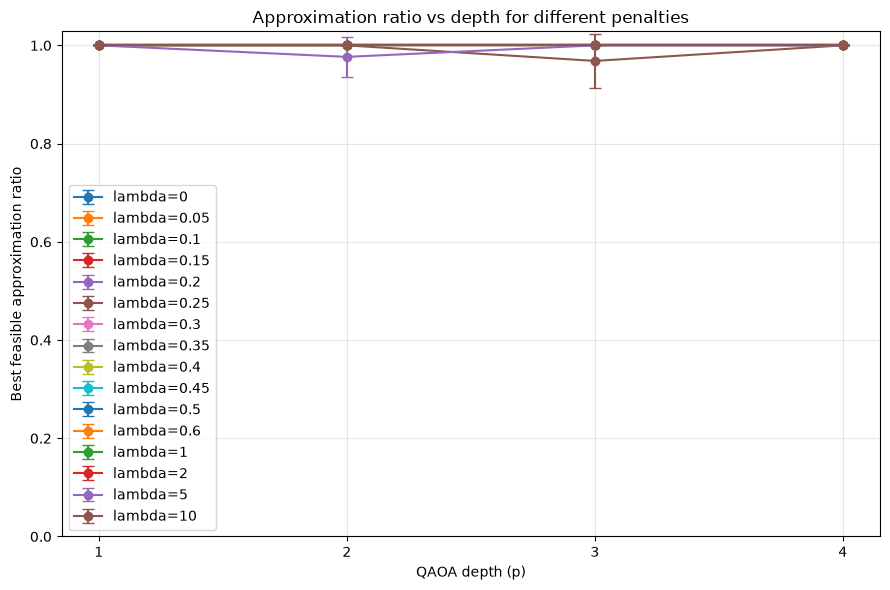

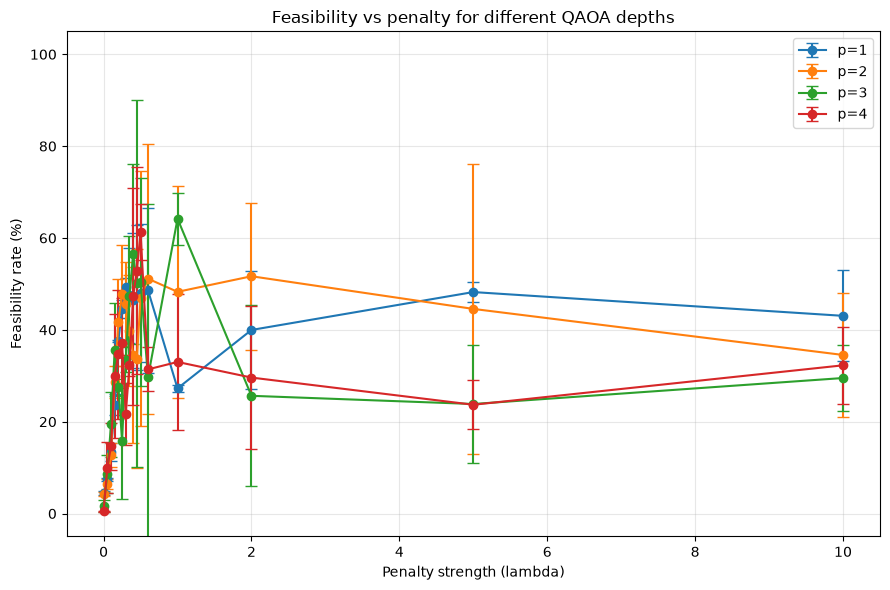

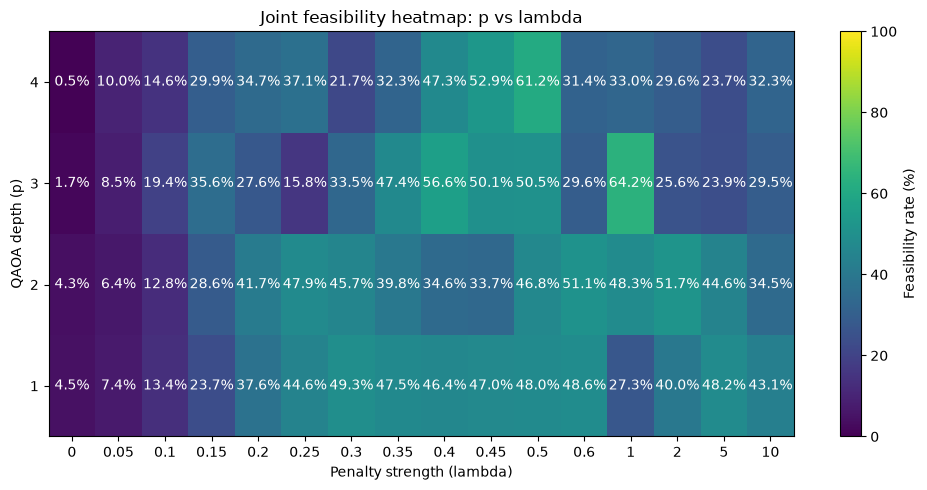


FINAL SUMMARY
Number of assets: 8
Assets selected (K): 4
Risk aversion (q): 0.5
Brute-force optimum: 2.234835576935609
Optimal portfolio: ['IBE.MC', 'BBVA.MC', 'CAF.MC', 'GOOGL']
Critical lambda: 0.21130890240828037
Main lambda: 10.0
Main experiment depth: 4
Main feasibility rate: 33.67%
Main QAOA portfolio: ['IBE.MC', 'BBVA.MC', 'CAF.MC', 'GOOGL']
Main QAOA objective: 2.234835576935609

Results saved in: C:\Users\fio\Documents\qff\quantum-optimization-qml-qff2026\src\results
Experiment completed.


In [ ]:
"""Portfolio optimization with QAOA (noiseless statevector simulation).

Runs:
1. Exact brute-force benchmark.
2. Main QAOA experiment.
3. Joint experiment varying QAOA depth p and penalty lambda.
4. Approximation ratio analysis.
5. Feasibility analysis and heatmap.

Set FAST_MODE=True for a quick screening run. Set FAST_MODE=False for
more reliable validation runs with more shots, iterations, and seeds.
"""

import json
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize

from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import LinearEqualityToPenalty


# ============================================================
# 0. CONFIGURATION
# ============================================================

DATA_PATH = Path("../data/parametros_8_activos.json")
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Financial problem
K = 4
Q_RISK = 0.5
LAMBDA_INITIAL = 10.0

# QAOA
P_MAIN = 4
DEPTHS = [1, 2, 3, 4]
MAIN_SEED = 42

# FAST_MODE=True for initial screening.
# FAST_MODE=False for full validation.
FAST_MODE = False

if FAST_MODE:
    SHOTS = 512
    MAX_ITER = 40
    EXPERIMENT_SEEDS = [42]
else:
    SHOTS = 4096
    MAX_ITER = 150
    EXPERIMENT_SEEDS = [11, 22, 42]

# Run the joint experiment instead of the two separate experiments.
RUN_JOINT_EXPERIMENT = True

VALIDATE_QUBO = True


# ============================================================
# 1. LOAD AND VALIDATE FINANCIAL DATA
# ============================================================

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH.resolve()}"
    )

with DATA_PATH.open("r", encoding="utf-8") as file:
    data = json.load(file)

n = int(data["n_activos"])
tickers = data["tickers"]
mu = np.asarray(data["mu"], dtype=float)
sigma = np.asarray(data["sigma"], dtype=float)

print("=" * 65)
print("PORTFOLIO OPTIMIZATION WITH QAOA")
print("=" * 65)
print(f"Assets: {n}")
print(f"Tickers: {tickers}")
print(f"Assets to select (K): {K}")
print(f"Risk aversion (q): {Q_RISK}")
print(f"FAST_MODE: {FAST_MODE}")
print(f"Shots per run: {SHOTS}")
print(f"COBYLA max evaluations: {MAX_ITER}")

if len(tickers) != n:
    raise ValueError("The number of tickers does not match n_activos.")
if mu.shape != (n,):
    raise ValueError(f"mu must have shape ({n},), got {mu.shape}.")
if sigma.shape != (n, n):
    raise ValueError(
        f"sigma must have shape ({n}, {n}), got {sigma.shape}."
    )
if not (0 <= K <= n):
    raise ValueError("K must be between 0 and n.")
if not np.all(np.isfinite(mu)) or not np.all(np.isfinite(sigma)):
    raise ValueError("Financial data contains NaN or infinite values.")
if not np.allclose(sigma, sigma.T, atol=1e-10):
    raise ValueError("The covariance matrix is not symmetric.")

# Remove tiny numerical asymmetries.
sigma = (sigma + sigma.T) / 2.0

eigenvalues = np.linalg.eigvalsh(sigma)
print("\nMinimum covariance eigenvalue:", float(eigenvalues.min()))
if eigenvalues.min() < -1e-8:
    raise ValueError("The covariance matrix is not positive semidefinite.")

print("Financial data validation passed.")


# ============================================================
# 2. FINANCIAL OBJECTIVE
# ============================================================

def portfolio_objective(x, mu_vector=mu, covariance=sigma, risk_aversion=Q_RISK):
    """Return f(x) = mu.T @ x - q * x.T @ sigma @ x."""
    x = np.asarray(x, dtype=float)
    expected_return = float(mu_vector @ x)
    portfolio_risk = float(x @ covariance @ x)
    return expected_return - risk_aversion * portfolio_risk


# ============================================================
# 3. EXACT BRUTE-FORCE BENCHMARK
# ============================================================

all_x = np.asarray(list(product([0, 1], repeat=n)), dtype=int)
selected_counts = all_x.sum(axis=1)
feasible_mask = selected_counts == K
infeasible_mask = ~feasible_mask

all_values = np.asarray([
    portfolio_objective(x) for x in all_x
], dtype=float)

feasible_solutions = all_x[feasible_mask]
feasible_values = all_values[feasible_mask]

if len(feasible_solutions) == 0:
    raise ValueError("No feasible portfolio exists for this K.")

best_idx = int(np.argmax(feasible_values))
optimal_x = feasible_solutions[best_idx]
optimal_value = float(feasible_values[best_idx])
# Store all optimal portfolios in case there are ties.
optimal_solutions = feasible_solutions[
    np.isclose(
        feasible_values,
        optimal_value,
        rtol=1e-9,
        atol=1e-9
    )
]

print("\n" + "=" * 65)
print("BRUTE-FORCE OPTIMUM")
print("=" * 65)
print("Total binary solutions:", len(all_x))
print("Feasible portfolios:", len(feasible_solutions))
print("Optimal assets:", [tickers[i] for i in range(n) if optimal_x[i] == 1])
print("Optimal bitstring (x0 to x[n-1]):", optimal_x.tolist())
print("Expected return:", float(mu @ optimal_x))
print("Portfolio variance:", float(optimal_x @ sigma @ optimal_x))
print("Optimal financial objective:", optimal_value)


# ============================================================
# 4. THEORETICAL CRITICAL LAMBDA
# ============================================================

if np.any(infeasible_mask):
    penalty_thresholds = (
        all_values[infeasible_mask] - optimal_value
    ) / (
        selected_counts[infeasible_mask] - K
    ) ** 2
    lambda_critical = max(0.0, float(np.max(penalty_thresholds)))
else:
    lambda_critical = 0.0

# Strictly above the critical value avoids an infeasible tie at the threshold.
lambda_main = max(
    LAMBDA_INITIAL,
    1.1 * lambda_critical + 1e-12
)

print("\n" + "=" * 65)
print("PENALTY ANALYSIS")
print("=" * 65)
print("Requested lambda:", LAMBDA_INITIAL)
print("Critical lambda:", lambda_critical)
print("Lambda used for main/depth experiment:", lambda_main)
print(
    "Requested lambda is theoretically sufficient:",
    LAMBDA_INITIAL > lambda_critical
)


# ============================================================
# 5. BUILD QUBO AND ISING HAMILTONIAN
# ============================================================

ISING_CACHE = {}


def build_ising_problem(lam):
    """Build the constrained portfolio model and convert it to Ising."""
    qp = QuadraticProgram()

    for ticker in tickers:
        qp.binary_var(name=ticker)

    # Maximize expected return minus risk.
    qp.maximize(
        linear=mu,
        quadratic=-Q_RISK * sigma
    )

    # Select exactly K assets.
    qp.linear_constraint(
        linear={ticker: 1 for ticker in tickers},
        sense="==",
        rhs=K,
        name="budget"
    )

    converter = LinearEqualityToPenalty(penalty=float(lam))
    qubo = converter.convert(qp)
    cost_hamiltonian, offset = qubo.to_ising()

    return qp, qubo, cost_hamiltonian, float(offset)


def get_ising_cached(lam):
    """Cache the converted model because it depends only on lambda."""
    key = float(lam)
    if key not in ISING_CACHE:
        ISING_CACHE[key] = build_ising_problem(key)
    return ISING_CACHE[key]


# Build one reference model for inspection and optional validation.
qp, qubo, cost_hamiltonian, offset = get_ising_cached(lambda_main)

print("\n" + "=" * 65)
print("MODEL FORMULATION")
print("=" * 65)
print("\nOriginal constrained problem:")
print(qp.prettyprint())
print("\nConverted QUBO:")
print(qubo.prettyprint())
print("\nIsing Hamiltonian:")
print(cost_hamiltonian)
print("Ising offset:", offset)


# ============================================================
# 6. VALIDATE THE QUBO AGAINST THE FINANCIAL FORMULATION
# ============================================================

if VALIDATE_QUBO:
    for x in all_x:
        financial_value = portfolio_objective(x)
        expected_qubo_value = (
            financial_value
            - lambda_main * (int(x.sum()) - K) ** 2
        )
        qiskit_qubo_value = float(qubo.objective.evaluate(x))

        if not np.isclose(
            qiskit_qubo_value,
            expected_qubo_value,
            rtol=1e-9,
            atol=1e-9
        ):
            raise AssertionError(
                "QUBO mismatch for x="
                f"{x.tolist()}: Qiskit={qiskit_qubo_value}, "
                f"expected={expected_qubo_value}"
            )

    print("\nQUBO validation passed for all binary solutions.")


# ============================================================
# 7. BITSTRING DECODING
# ============================================================

def decode_bitstring(key, num_qubits):
    """Decode Qiskit's displayed bitstring into x[0], ..., x[n-1]."""
    bits = key.replace(" ", "")[::-1]
    if len(bits) != num_qubits:
        raise ValueError(
            f"Expected {num_qubits} bits, received {len(bits)}: {key}"
        )
    return np.asarray([int(bit) for bit in bits], dtype=int)


# ============================================================
# 8. QAOA EXECUTION FUNCTION
# ============================================================

ESTIMATOR = StatevectorEstimator()


def run_qaoa(lam, p, seed=42, shots=SHOTS, maxiter=MAX_ITER,
             initial_params=None):
    """Optimize QAOA parameters, sample the circuit, and evaluate bitstrings."""

    if p < 1:
        raise ValueError("QAOA depth p must be at least 1.")
    if shots < 1:
        raise ValueError("shots must be at least 1.")
    if maxiter < 1:
        raise ValueError("maxiter must be at least 1.")
    if lam < 0:
        raise ValueError("Penalty lambda must be non-negative.")

    _, _, hamiltonian, offset_local = get_ising_cached(lam)

    # flatten=True reduces parameter-binding overhead.
    ansatz_no_meas = QAOAAnsatz(
        cost_operator=hamiltonian,
        reps=p,
        flatten=True
    )
    ansatz_meas = ansatz_no_meas.copy()
    ansatz_meas.measure_all()

    def cost_function(params):
        pub = (ansatz_no_meas, hamiltonian, params)
        energy = ESTIMATOR.run([pub]).result()[0].data.evs
        return float(np.asarray(energy).item())

    rng = np.random.default_rng(seed)

    if initial_params is None:
        x0 = rng.uniform(0.0, np.pi, ansatz_no_meas.num_parameters)
    else:
        x0 = np.asarray(initial_params, dtype=float)
        if x0.shape != (ansatz_no_meas.num_parameters,):
            raise ValueError(
                "initial_params has the wrong size: expected "
                f"{ansatz_no_meas.num_parameters}, got {x0.size}."
            )

    optimization = minimize(
        cost_function,
        x0,
        method="COBYLA",
        options={
            "maxiter": maxiter,
            "rhobeg": 0.5,
            "tol": 1e-2
        }
    )

    sampler = StatevectorSampler(seed=seed)
    pub_final = (ansatz_meas, optimization.x)
    samples = sampler.run([pub_final], shots=shots).result()[0].data.meas.get_counts()

    records = []
    for bitstring, count in samples.items():
        x = decode_bitstring(bitstring, n)
        num_selected = int(x.sum())
        is_feasible = num_selected == K
        financial_value = portfolio_objective(x)
        penalized_cost = (
            -financial_value + lam * (num_selected - K) ** 2
        )

        records.append({
            "bitstring": bitstring,
            "x": x,
            "count": int(count),
            "probability": float(count) / shots,
            "selected": num_selected,
            "feasible": is_feasible,
            "financial_value": financial_value,
            "penalized_cost": penalized_cost
        })

    total_shots = sum(record["count"] for record in records)

    # Probability of sampling any globally optimal portfolio.
    optimal_shots = sum(
        record["count"]
        for record in records
        if any(np.array_equal(record["x"], solution) for solution in optimal_solutions))

    optimal_solution_probability = (optimal_shots / total_shots if total_shots else 0.0)

    feasible_records = [record for record in records if record["feasible"]]
    feasible_shots = sum(record["count"] for record in feasible_records)
    feasibility_rate = feasible_shots / total_shots if total_shots else 0.0

    best_feasible = max(
        feasible_records,
        key=lambda record: record["financial_value"],
        default=None
    )
    most_frequent = max(
        records,
        key=lambda record: record["count"],
        default=None
    )

    return {
        "p": int(p),
        "lambda": float(lam),
        "seed": int(seed),
        "best_feasible": best_feasible,
        "most_frequent": most_frequent,
        "feasibility_rate": float(feasibility_rate),
        "optimizer_energy": float(optimization.fun),
        "optimal_solution_probability": float(optimal_solution_probability),
        "energy_with_offset": float(optimization.fun + offset_local),
        "optimizer_success": bool(optimization.success),
        "optimizer_message": str(optimization.message),
        "nfev": int(optimization.nfev),
        "optimal_params": np.asarray(optimization.x, dtype=float),
        "samples": samples,
        "records": records,
        "offset": float(offset_local)
    }


# ============================================================
# 9. RUN CACHE
# ============================================================

RUN_CACHE = {}


def get_cached_run(lam, p, seed, shots=SHOTS, maxiter=MAX_ITER):
    """Reuse only runs with exactly the same experimental settings."""
    key = (
        float(lam),
        int(p),
        int(seed),
        int(shots),
        int(maxiter)
    )

    if key not in RUN_CACHE:
        print(
            f"\nRunning QAOA | p={p} | lambda={lam:.6g} | "
            f"seed={seed} | shots={shots} | maxiter={maxiter}"
        )
        RUN_CACHE[key] = run_qaoa(
            lam=lam,
            p=p,
            seed=seed,
            shots=shots,
            maxiter=maxiter
        )

    return RUN_CACHE[key]


# ============================================================
# 10. MAIN EXPERIMENT
# ============================================================

print("\n" + "=" * 65)
print("MAIN QAOA EXPERIMENT")
print("=" * 65)

main_result = get_cached_run(
    lam=lambda_main,
    p=P_MAIN,
    seed=MAIN_SEED,
    shots=SHOTS,
    maxiter=MAX_ITER
)

best_feasible = main_result["best_feasible"]

print("Depth:", P_MAIN)
print("Lambda:", lambda_main)
print("Feasibility rate:", f"{main_result['feasibility_rate']:.2%}")
print(
    "Optimal solution probability:",
    f"{main_result['optimal_solution_probability']:.2%}"
)
print("Optimizer success:", main_result["optimizer_success"])
print("Optimizer evaluations:", main_result["nfev"])

if best_feasible is not None:
    qaoa_x = best_feasible["x"]
    qaoa_value = best_feasible["financial_value"]
    qaoa_assets = [tickers[i] for i in range(n) if qaoa_x[i] == 1]
    optimality_gap = optimal_value - qaoa_value

    print("\nBest feasible QAOA portfolio:")
    print("Assets:", qaoa_assets)
    print("Binary solution:", qaoa_x.tolist())
    print("Financial objective:", qaoa_value)
    print("Exact optimum:", optimal_value)
    print("Optimality gap:", optimality_gap)

    if optimal_value > 0:
        approximation_ratio = qaoa_value / optimal_value
        print("Approximation ratio:", approximation_ratio)
    else:
        approximation_ratio = np.nan
        print("Approximation ratio not reported: optimum is not positive.")
else:
    qaoa_value = np.nan
    approximation_ratio = np.nan
    print("No feasible portfolio was sampled.")

most_frequent = main_result["most_frequent"]
if most_frequent is not None:
    print("\nMost frequent bitstring:", most_frequent["bitstring"])
    print("Frequency:", most_frequent["count"])
    print("Feasible:", most_frequent["feasible"])



# ============================================================
# 11. JOINT EXPERIMENT: DEPTH p AND PENALTY LAMBDA
# ============================================================

if RUN_JOINT_EXPERIMENT:

    print("\n" + "=" * 65)
    print("JOINT EXPERIMENT: VARYING p AND LAMBDA")
    print("=" * 65)

    # Build lambda grid around the critical penalty.
    if lambda_critical > 1e-12:

        lambda_values = [
            0.0,
            lambda_critical,
            2.0 * lambda_critical,
            5.0 * lambda_critical,
            lambda_main
        ]

    else:
        # Fallback if the critical lambda is zero.
        lambda_scale = max(float(np.ptp(all_values)), 1e-6)

        lambda_values = [
            0.0,
            0.05 * lambda_scale,
            0.1 * lambda_scale,
            0.5 * lambda_scale,
            lambda_main
        ]

    # Remove duplicates, preserving numeric order.
    lambda_values = sorted(set(float(x) for x in lambda_values))

    print("Depth values:", DEPTHS)
    print("Lambda values:", lambda_values)
    print("Seeds:", EXPERIMENT_SEEDS)

    print(
        "Total executions:",
        len(DEPTHS) * len(lambda_values) * len(EXPERIMENT_SEEDS)
    )

    joint_results = []

    for p in DEPTHS:

        for lam_test in lambda_values:

            for seed in EXPERIMENT_SEEDS:

                result = get_cached_run(
                    lam=lam_test,
                    p=p,
                    seed=seed,
                    shots=SHOTS,
                    maxiter=MAX_ITER
                )

                best = result["best_feasible"]

                if best is not None:

                    best_objective = float(best["financial_value"])

                    optimality_gap = (
                        optimal_value - best_objective
                    )

                    approximation_ratio = (
                        best_objective / optimal_value
                        if optimal_value > 0
                        else np.nan
                    )

                    best_portfolio = [
                        tickers[i]
                        for i in range(n)
                        if best["x"][i] == 1
                    ]

                else:

                    best_objective = np.nan
                    optimality_gap = np.nan
                    approximation_ratio = np.nan
                    best_portfolio = None

                joint_results.append({

                    "p": p,
                    "lambda": lam_test,
                    "seed": seed,

                    "approximation_ratio": approximation_ratio,
                    "optimality_gap": optimality_gap,
                    "best_objective": best_objective,

                    "feasibility_rate": result["feasibility_rate"],

                    "optimal_solution_probability":
                        result["optimal_solution_probability"],

                    "nfev": result["nfev"],
                    "optimizer_success": result["optimizer_success"],

                    "best_portfolio": str(best_portfolio)

                })

                print(
                    f"p={p} | lambda={lam_test:.6g} | "
                    f"seed={seed} | "
                    f"feasibility={result['feasibility_rate']:.2%} | "
                    f"optimal_probability="
                    f"{result['optimal_solution_probability']:.2%}"
                )

    # --------------------------------------------------------
    # 11.1 SAVE RAW RESULTS
    # --------------------------------------------------------

    joint_df = pd.DataFrame(joint_results)

    joint_df.to_csv(
        OUTPUT_DIR / "joint_results.csv",
        index=False
    )

    print("\nJoint experiment results:")
    print(joint_df.to_string(index=False))

    # --------------------------------------------------------
    # 11.2 GROUP RESULTS BY (p, lambda)
    # --------------------------------------------------------

    joint_summary = (
        joint_df
        .groupby(["p", "lambda"])
        .agg(
            approximation_ratio_mean=(
                "approximation_ratio", "mean"
            ),
            approximation_ratio_std=(
                "approximation_ratio", "std"
            ),
            feasibility_mean=(
                "feasibility_rate", "mean"
            ),
            feasibility_std=(
                "feasibility_rate", "std"
            ),
            optimal_probability_mean=(
                "optimal_solution_probability", "mean"
            ),
            optimal_probability_std=(
                "optimal_solution_probability", "std"
            ),
            best_objective_mean=(
                "best_objective", "mean"
            ),
            nfev_mean=(
                "nfev", "mean"
            ),
            optimizer_success_rate=(
                "optimizer_success", "mean"
            )
        )
        .reset_index()
    )

    joint_summary.to_csv(
        OUTPUT_DIR / "joint_summary.csv",
        index=False
    )

    print("\nJoint experiment summary:")
    print(joint_summary.to_string(index=False))

    # --------------------------------------------------------
    # 11.3 APPROXIMATION RATIO VS DEPTH
    #      One curve per lambda
    # --------------------------------------------------------

    plt.figure(figsize=(9, 6))

    for lam_test, group in joint_summary.groupby("lambda"):

        group = group.sort_values("p")

        plt.errorbar(
            group["p"],
            group["approximation_ratio_mean"],
            yerr=group["approximation_ratio_std"].fillna(0.0),
            marker="o",
            capsize=4,
            label=f"lambda={lam_test:.4g}"
        )

    plt.xlabel("QAOA depth (p)")
    plt.ylabel("Best feasible approximation ratio")
    plt.title("Approximation ratio vs depth for different penalties")

    plt.xticks(DEPTHS)
    plt.ylim(bottom=0)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "joint_approximation_ratio_vs_depth.png",
        dpi=300
    )

    plt.show()

    # --------------------------------------------------------
    # 11.4 FEASIBILITY RATE VS LAMBDA
    #      One curve per depth
    # --------------------------------------------------------

    plt.figure(figsize=(9, 6))

    for p_test, group in joint_summary.groupby("p"):

        group = group.sort_values("lambda")

        plt.errorbar(
            group["lambda"],
            group["feasibility_mean"] * 100.0,
            yerr=group["feasibility_std"].fillna(0.0) * 100.0,
            marker="o",
            capsize=4,
            label=f"p={p_test}"
        )

    plt.xlabel("Penalty strength (lambda)")
    plt.ylabel("Feasibility rate (%)")
    plt.title("Feasibility vs penalty for different QAOA depths")

    plt.ylim(-5, 105)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "joint_feasibility_vs_lambda.png",
        dpi=300
    )

    plt.show()
    # --------------------------------------------------------
    # 11.5 FEASIBILITY HEATMAP
    # --------------------------------------------------------

    feasibility_pivot = joint_summary.pivot(
        index="p",
        columns="lambda",
        values="feasibility_mean"
    ).sort_index()

    plt.figure(figsize=(10, 5))

    image = plt.imshow(
        feasibility_pivot.values * 100.0,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=100
    )

    plt.colorbar(
        image,
        label="Feasibility rate (%)"
    )

    plt.xticks(
        np.arange(len(feasibility_pivot.columns)),
        [f"{value:.4g}" for value in feasibility_pivot.columns]
    )

    plt.yticks(
        np.arange(len(feasibility_pivot.index)),
        feasibility_pivot.index
    )

    plt.xlabel("Penalty strength (lambda)")
    plt.ylabel("QAOA depth (p)")
    plt.title("Joint feasibility heatmap: p vs lambda")

    # Display values inside each cell.
    for i in range(feasibility_pivot.shape[0]):

        for j in range(feasibility_pivot.shape[1]):

            value = feasibility_pivot.iloc[i, j] * 100.0

            plt.text(
                j,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="white"
            )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "joint_feasibility_heatmap.png",
        dpi=300
    )

    plt.show()



# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FINAL SUMMARY")
print("=" * 65)
print("Number of assets:", n)
print("Assets selected (K):", K)
print("Risk aversion (q):", Q_RISK)
print("Brute-force optimum:", optimal_value)
print("Optimal portfolio:", [tickers[i] for i in range(n) if optimal_x[i] == 1])
print("Critical lambda:", lambda_critical)
print("Main lambda:", lambda_main)
print("Main experiment depth:", P_MAIN)
print("Main feasibility rate:", f"{main_result['feasibility_rate']:.2%}")

if best_feasible is not None:
    print(
        "Main QAOA portfolio:",
        [tickers[i] for i in range(n) if best_feasible["x"][i] == 1]
    )
    print("Main QAOA objective:", best_feasible["financial_value"])
else:
    print("Main QAOA did not sample a feasible portfolio.")

print("\nResults saved in:", OUTPUT_DIR.resolve())
print("Experiment completed.")
